# Fase 2 · Análisis exploratorio

**Pregunta del proyecto:** ¿cuántas pernoctaciones hoteleras tendrán la Costa Blanca y Benidorm
en los próximos 1–12 meses, y qué factores lo explican?

Este notebook describe las series antes de modelar y fija las decisiones que usaremos en las fases 3 y 4:

1. Visión general y tendencia
2. Estacionalidad: ¿se está desestacionalizando la Costa Blanca?
3. Residentes en España frente a extranjeros
4. Benidorm frente al resto de la Costa Blanca
5. Oferta: plazas, ocupación y estancia media
6. Efecto de Semana Santa
7. COVID: cuándo se recuperó la normalidad
8. El aeropuerto como indicador adelantado
9. Autocorrelación y estacionariedad
10. Modelo de referencia (ingenuo estacional)
11. Conclusiones y decisiones para modelar

**Datos:** `data/processed/dataset_mensual.csv`, generado con `python src/descarga.py`
(INE · Encuesta de Ocupación Hotelera y Eurostat · pasajeros del aeropuerto de Alicante-Elche).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "outputs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Estilo: fondo claro, rejilla discreta, una paleta categórica fija
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
    "font.size": 10.5,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f} M" if x >= 1e6 else f"{x/1e3:.0f} k")

def guardar(nombre):
    plt.savefig(FIG / f"{nombre}.png", bbox_inches="tight")
    plt.show()

d = pd.read_csv(RAIZ / "data" / "processed" / "dataset_mensual.csv", parse_dates=["fecha"]).set_index("fecha")
y = d["costa_blanca_pernoctaciones_total"]          # variable objetivo
print(f"{len(d)} meses: {d.index.min():%Y-%m} → {d.index.max():%Y-%m} · {d.shape[1]} columnas")
d[["costa_blanca_pernoctaciones_total", "benidorm_pernoctaciones_total",
   "aeropuerto_pasajeros_total", "dias_semana_santa", "covid"]].tail()

333 meses: 1999-01 → 2026-09 · 38 columnas


,costa_blanca_pernoctaciones_total,benidorm_pernoctaciones_total,aeropuerto_pasajeros_total,dias_semana_santa,covid
fecha,,,,,
2026-05-01,1717473.0,1086463.0,2068589.0,0,0
2026-06-01,1796973.0,1140397.0,2122981.0,0,0
2026-07-01,2143461.0,1304819.0,NaN,0,0
2026-08-01,2275485.0,1357135.0,NaN,0,0
2026-09-01,1864447.0,1160258.0,NaN,0,0


## 1. Visión general y tendencia

La variable objetivo es el **total de pernoctaciones hoteleras en la Costa Blanca**
(residentes en España + extranjero). La banda gris marca el periodo COVID.

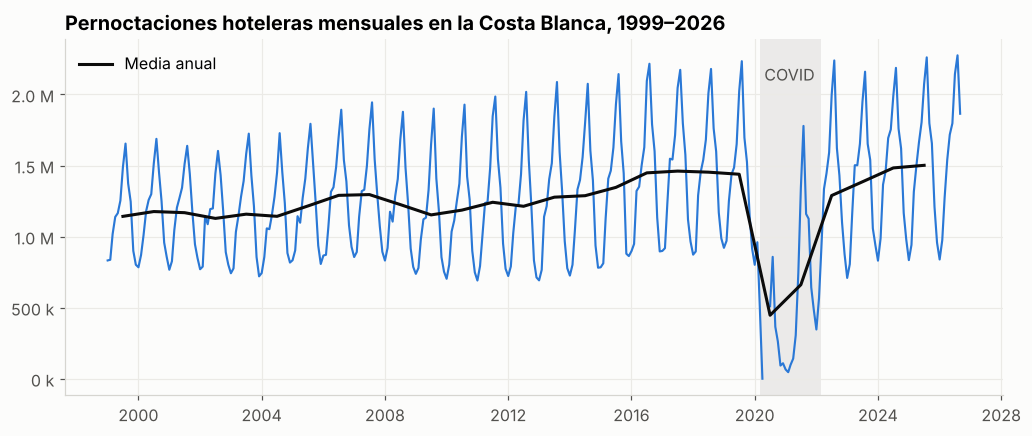

Pernoctaciones anuales (millones), años completos:
fecha
1999    13.71
2007    15.55
2009    13.83
2019    17.27
2023    16.63
2024    17.80
2025    18.02


In [2]:
covid = d.index[d.covid == 1]
fig, ax = plt.subplots()
ax.axvspan(covid.min(), covid.max(), color=GRIS, alpha=0.15, lw=0)
ax.plot(y.index, y, color=AZUL, lw=1.4)
anual = y.resample("YS").mean()["1999":"2025"]          # solo años completos
ax.plot(anual.index + pd.DateOffset(months=6), anual, color="#0b0b0b", lw=2, label="Media anual")
ax.yaxis.set_major_formatter(miles)
ax.set_title("Pernoctaciones hoteleras mensuales en la Costa Blanca, 1999–2026")
ax.text(covid.min(), y.max() * 0.97, " COVID", color="#52514e", va="top")
ax.legend(loc="upper left")
guardar("01_serie_completa")

tot = y.groupby(y.index.year).agg(["sum", "count"])
tot = tot[tot["count"] == 12]["sum"].div(1e6).round(2)
print("Pernoctaciones anuales (millones), años completos:")
print(tot.loc[[1999, 2007, 2009, 2019, 2023, 2024, 2025]].to_string())

**Lectura:**
- La serie es casi plana entre 1999 y 2014 (13,5–15,5 millones al año), con una caída en la crisis de 2009.
- Entre 2015 y 2017 da un salto hasta unos 17,5 millones, se estanca hasta 2019 y, tras el hundimiento
  del COVID, **2024 y 2025 superan ya el máximo previo** (17,8 y 18,0 millones).
- La estacionalidad es mucho mayor que la tendencia: el verano duplica o triplica al invierno.
  Esto ya dice que el modelo tiene que capturar, sobre todo, **el patrón mensual**.

## 2. Estacionalidad: ¿se está desestacionalizando la Costa Blanca?

Se suele decir que el turismo de sol y playa se reparte cada vez más a lo largo del año.
Comprobamos el peso de cada mes en tres periodos.

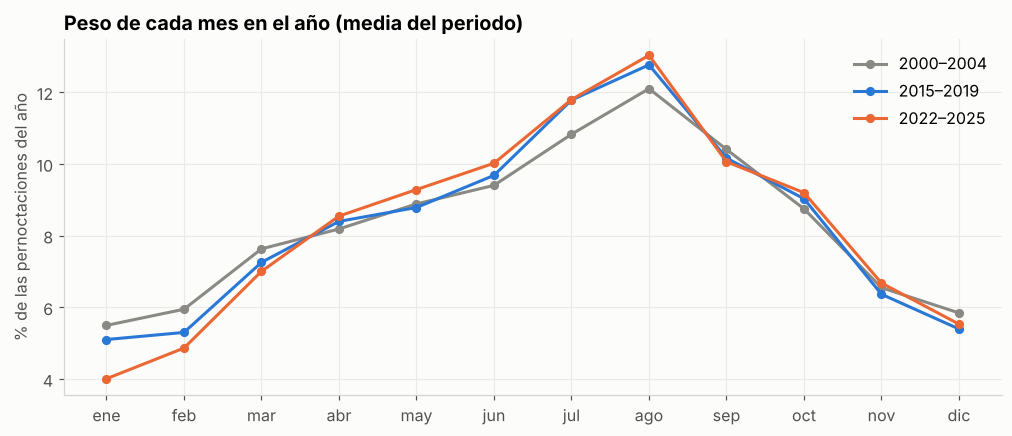

Mes más alto / mes más bajo: {'2000–2004': 2.2, '2015–2019': 2.5, '2022–2025': 3.25}


,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
2000–2004,5.5,5.9,7.6,8.2,8.9,9.4,10.8,12.1,10.4,8.7,6.5,5.8
2015–2019,5.1,5.3,7.3,8.4,8.8,9.7,11.8,12.8,10.2,9.0,6.4,5.4
2022–2025,4.0,4.9,7.0,8.5,9.3,10.0,11.8,13.0,10.1,9.2,6.7,5.5


In [3]:
def perfil(serie, a, b):
    s = serie[str(a):str(b)]
    p = s.groupby(s.index.month).mean()
    return p / p.sum() * 100

periodos = {"2000–2004": (2000, 2004), "2015–2019": (2015, 2019), "2022–2025": (2022, 2025)}
perfiles = pd.DataFrame({k: perfil(y, *v) for k, v in periodos.items()})
perfiles.index = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

fig, ax = plt.subplots()
for (k, col) in zip(perfiles, [GRIS, AZUL, NARANJA]):
    ax.plot(perfiles.index, perfiles[k], marker="o", ms=5, color=col, label=k)
ax.set_ylabel("% de las pernoctaciones del año")
ax.set_title("Peso de cada mes en el año (media del periodo)")
ax.legend()
guardar("02_perfil_estacional")

ratio = (perfiles.max() / perfiles.min()).round(2)
print("Mes más alto / mes más bajo:", ratio.to_dict())
perfiles.round(1).T

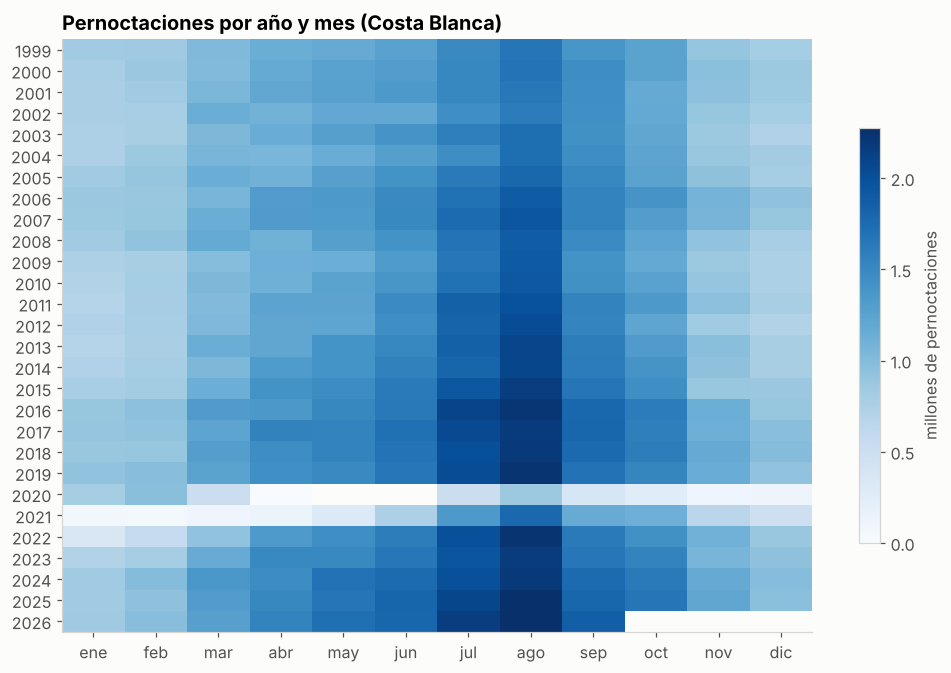

Enero, miles de pernoctaciones: media 2016–2019 = 898 · media 2024–2026 = 835


In [4]:
# Mapa de calor año × mes, en millones
tabla = y.to_frame("v").assign(a=y.index.year, m=y.index.month).pivot(index="a", columns="m", values="v") / 1e6
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(tabla, aspect="auto", cmap="Blues")
ax.set_xticks(range(12), perfiles.index); ax.set_yticks(range(len(tabla)), tabla.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("millones de pernoctaciones")
ax.set_title("Pernoctaciones por año y mes (Costa Blanca)")
guardar("03_mapa_calor")

ene = y[y.index.month == 1]
print("Enero, miles de pernoctaciones: media 2016–2019 =", round(ene["2016":"2019"].mean() / 1e3),
      "· media 2024–2026 =", round(ene["2024":"2026"].mean() / 1e3))

**Lectura: no, se está estacionalizando más.**
- La relación entre el mes más alto (agosto) y el más bajo (enero) pasa de **2,2** a principios de siglo
  a **2,5** antes del COVID y a **3,25** después.
- Enero pierde peso: del 5,1 % al 4,0 % del año. Los eneros de 2024–2026 rondan las 835.000
  pernoctaciones, por debajo de los cerca de 900.000 de 2016–2019, aunque el total anual sea mayor.
- El crecimiento reciente se concentra en primavera y verano.

Es un hallazgo con interés de negocio. Una hipótesis que habría que contrastar con otras fuentes:
el turismo de invierno (estancias largas de jubilados europeos y nacionales) no ha vuelto al nivel anterior,
o se ha ido a otros tipos de alojamiento.

**Para el modelo:** el patrón estacional **no es fijo**. Conviene dar más peso a los años recientes
o dejar que el modelo aprenda un perfil que cambia (por ejemplo, retardos de 12 meses en vez de solo
el mes como variable).

## 3. Residentes en España frente a extranjeros

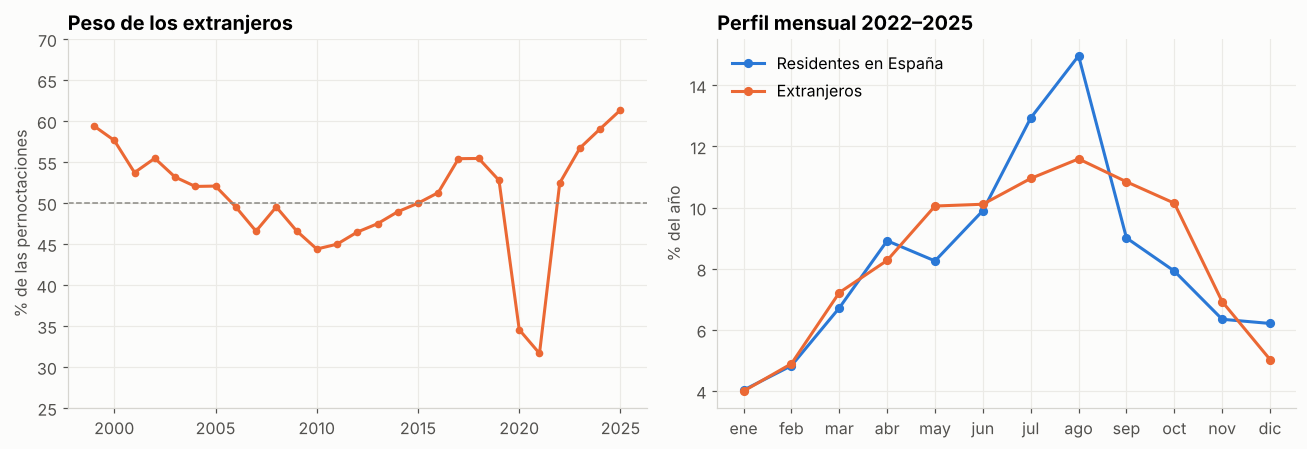

Peso de extranjeros: {1999: 59.4, 2010: 44.4, 2019: 52.8, 2023: 56.7, 2025: 61.3}


In [5]:
esp, ext = d["costa_blanca_pernoctaciones_esp"], d["costa_blanca_pernoctaciones_ext"]
cuota = (ext / y * 100).groupby(y.index.year).mean().loc[:2025]   # años completos

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(cuota.index, cuota, color=NARANJA, marker="o", ms=4)
ax.axhline(50, color=GRIS, lw=1, ls="--")
ax.set_ylabel("% de las pernoctaciones"); ax.set_ylim(25, 70)
ax.set_title("Peso de los extranjeros")

ax = axes[1]
pe, px = perfil(esp, 2022, 2025), perfil(ext, 2022, 2025)
ax.plot(perfiles.index, pe.values, color=AZUL, marker="o", ms=5, label="Residentes en España")
ax.plot(perfiles.index, px.values, color=NARANJA, marker="o", ms=5, label="Extranjeros")
ax.set_ylabel("% del año"); ax.set_title("Perfil mensual 2022–2025")
ax.legend()
plt.tight_layout()
guardar("04_residentes_extranjeros")

print("Peso de extranjeros:", cuota.loc[[1999, 2010, 2019, 2023, 2025]].round(1).to_dict())

**Lectura:**
- El peso de los extranjeros bajó del 59 % (1999) al 44 % (2010), se recuperó hasta 2019 y
  **desde el COVID no para de subir: 61 % en 2025**, máximo de la serie.
- Los dos públicos tienen calendarios distintos. Los españoles se concentran en julio y agosto
  (un 28 % del año entre los dos meses). Los extranjeros se reparten de mayo a octubre, con septiembre
  casi igual que agosto.

**Para el modelo:** conviene modelar las dos series por separado y sumarlas, o al menos comparar
esa opción con modelar el total. Cada una responde a factores distintos (vacaciones escolares
frente a vuelos internacionales).

## 4. Benidorm frente al resto de la Costa Blanca

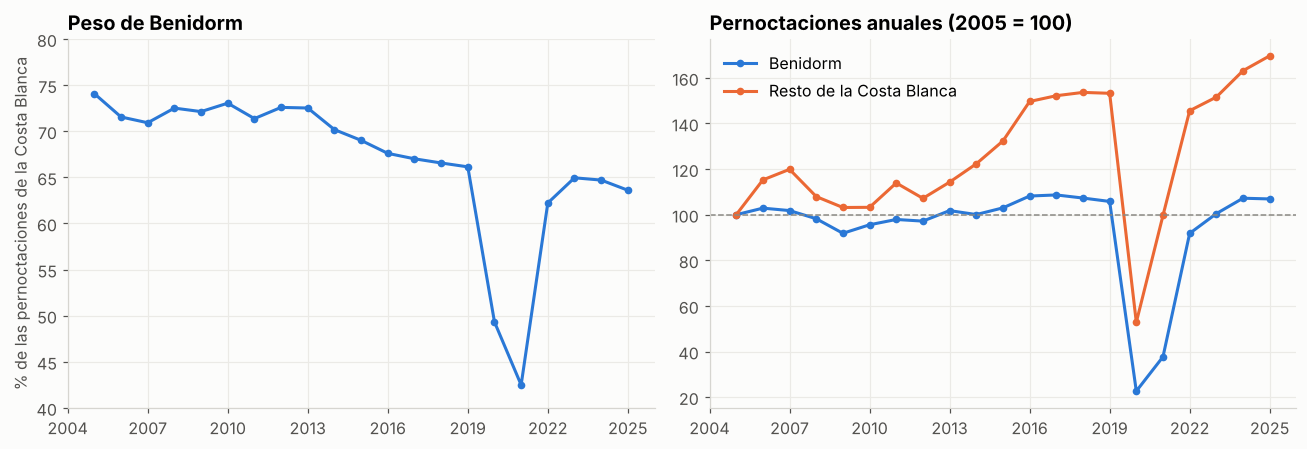

Índice 2025 (2005 = 100): Benidorm 107 · resto 170


In [6]:
ben = d["benidorm_pernoctaciones_total"]
peso_ben = (ben / y * 100).groupby(y.index.year).mean().dropna().loc[:2025]
resto = (y - ben)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(peso_ben.index, peso_ben, color=AZUL, marker="o", ms=4)
ax.set_ylim(40, 80); ax.set_ylabel("% de las pernoctaciones de la Costa Blanca")
ax.set_title("Peso de Benidorm")
ax = axes[1]
idx = lambda s: s.groupby(s.index.year).sum()[lambda x: x.index.isin(range(2005, 2026))]
b, r = idx(ben), idx(resto)
ax.plot(b.index, b / b.loc[2005] * 100, color=AZUL, marker="o", ms=4, label="Benidorm")
ax.plot(r.index, r / r.loc[2005] * 100, color=NARANJA, marker="o", ms=4, label="Resto de la Costa Blanca")
ax.axhline(100, color=GRIS, lw=1, ls="--")
ax.set_title("Pernoctaciones anuales (2005 = 100)"); ax.legend()
for ax in axes:
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
guardar("05_benidorm_resto")
print("Índice 2025 (2005 = 100): Benidorm", round(b.loc[2025] / b.loc[2005] * 100),
      "· resto", round(r.loc[2025] / r.loc[2005] * 100))

**Lectura:** Benidorm sigue siendo la mayoría de la Costa Blanca, pero pierde peso de forma continua:
del 74 % en 2005 al 64 % en 2025. Benidorm tiene solo un 7 % más de pernoctaciones que en 2005, mientras que el resto
de la costa ha crecido un 70 %. El crecimiento de la zona viene de fuera de Benidorm.

**Para el modelo:** Benidorm (desde 2005) puede modelarse como segunda serie objetivo. Su
comportamiento es más estable, probablemente porque su capacidad hotelera ya está casi al límite.

## 5. Oferta: plazas, ocupación y estancia media

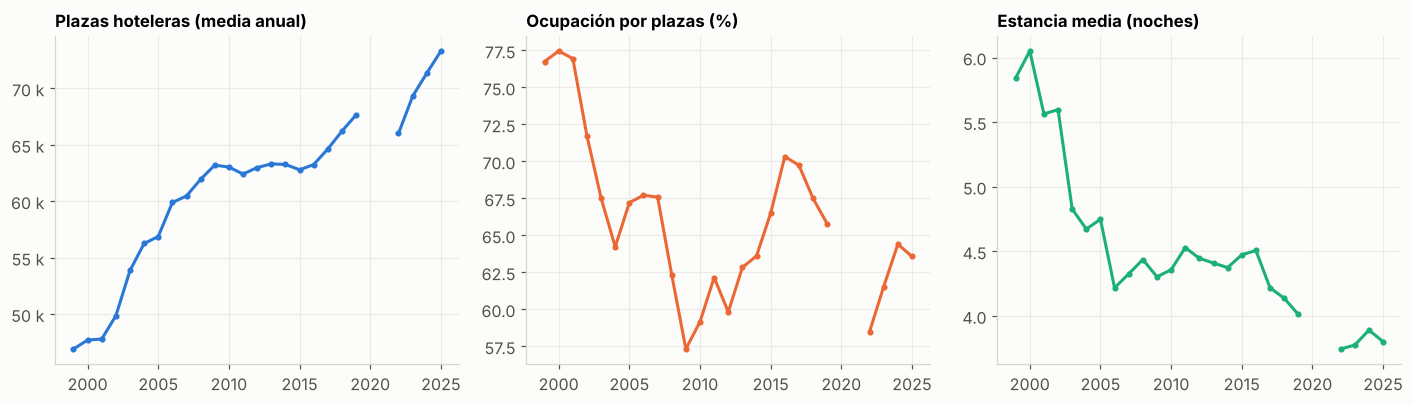

,plazas,ocupacion,estancia
fecha,,,
1999,46906.8,76.8,5.8
2007,60470.8,67.6,4.3
2019,67656.2,65.8,4.0
2025,73318.7,63.6,3.8


In [7]:
anual = d.groupby(d.index.year).agg(
    plazas=("costa_blanca_plazas_total", "mean"),
    ocupacion=("costa_blanca_ocupacion_plazas_total", "mean"),
    estancia=("costa_blanca_estancia_media", "mean"),
).loc[:2025]
anual.loc[[2020, 2021]] = np.nan                    # hueco: años COVID

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, titulo, color in zip(
    axes, ["plazas", "ocupacion", "estancia"],
    ["Plazas hoteleras (media anual)", "Ocupación por plazas (%)", "Estancia media (noches)"],
    [AZUL, NARANJA, AQUA],
):
    ax.plot(anual.index, anual[col], color=color, marker="o", ms=3)
    ax.set_title(titulo, fontsize=11)
axes[0].yaxis.set_major_formatter(miles)
plt.tight_layout()
guardar("06_oferta")
anual.loc[[1999, 2007, 2019, 2025]].round(1)

**Lectura** (sin 2020 y 2021, y sin 2026, que aún no está completo):
- **Las plazas crecen un 56 %** entre 1999 y 2025 (de unas 47.000 a 73.000), más deprisa que la demanda.
  Por eso la ocupación media es hoy menor que a principios de siglo (64 % frente a 77 %).
- **La estancia media cae de 5,8 a 3,8 noches.** Llegan más viajeros, pero se quedan menos tiempo.
  Es la tendencia general del turismo europeo: escapadas más cortas y frecuentes.

**Para el modelo:** las plazas abiertas son casi una "capacidad máxima" del mes. Son candidatas a
variable explicativa, pero el INE las publica a la vez que las pernoctaciones, así que solo valen con
retardo (el dato del mes anterior), igual que el resto de variables del INE.

## 6. Efecto de Semana Santa

La Semana Santa cae en marzo o en abril según el año. Medimos qué parte de las pernoctaciones de
marzo + abril cae en marzo, según cuántos días de Semana Santa (Domingo de Ramos a Lunes de Pascua)
tenga marzo ese año.

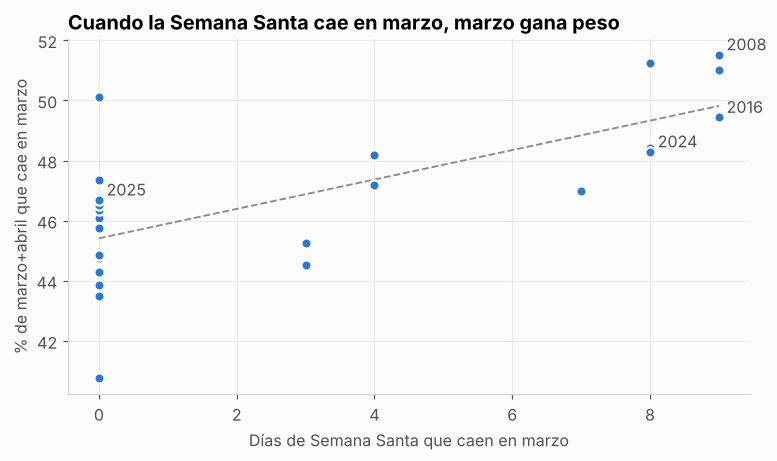

Correlación: 0.70 · cada día de Semana Santa en marzo traslada 0.49 puntos de abril a marzo
                       mean  count
dias_ss_marzo                     
Semana Santa en abril  45.7     19
Semana Santa en marzo  49.6      7


In [8]:
filas = []
for a in range(1999, 2027):
    if a in (2020, 2021):
        continue
    m, ab = y.get(pd.Timestamp(f"{a}-03-01")), y.get(pd.Timestamp(f"{a}-04-01"))
    if pd.isna(m) or pd.isna(ab):
        continue
    filas.append({"año": a, "dias_ss_marzo": d.loc[f"{a}-03-01", "dias_semana_santa"], "cuota_marzo": m / (m + ab) * 100})
ss = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(ss.dias_ss_marzo, ss.cuota_marzo, color=AZUL, s=45, edgecolor="#fcfcfb", lw=1.5, zorder=3)
for _, f in ss[ss.año.isin([2008, 2016, 2024, 2025])].iterrows():
    ax.annotate(int(f.año), (f.dias_ss_marzo, f.cuota_marzo), xytext=(5, 3), textcoords="offset points", color="#52514e")
b1, b0 = np.polyfit(ss.dias_ss_marzo, ss.cuota_marzo, 1)
xs = np.array([0, 9]); ax.plot(xs, b0 + b1 * xs, color=GRIS, lw=1.2, ls="--")
ax.set_xlabel("Días de Semana Santa que caen en marzo"); ax.set_ylabel("% de marzo+abril que cae en marzo")
ax.set_title("Cuando la Semana Santa cae en marzo, marzo gana peso")
guardar("07_semana_santa")
r = np.corrcoef(ss.dias_ss_marzo, ss.cuota_marzo)[0, 1]
print(f"Correlación: {r:.2f} · cada día de Semana Santa en marzo traslada {b1:.2f} puntos de abril a marzo")
print(ss.groupby(ss.dias_ss_marzo >= 5).cuota_marzo.agg(["mean", "count"]).round(1)
        .rename(index={False: "Semana Santa en abril", True: "Semana Santa en marzo"}))

**Lectura:** el efecto es claro (correlación de 0,7). Con la Semana Santa en abril, marzo se lleva
de media un 46 % de las pernoctaciones de marzo + abril; con la Semana Santa en marzo, casi un 50 %.
Cada día de Semana Santa que cae en marzo traslada medio punto de abril a marzo.

Esto importa para los errores: un modelo que solo mire "el mismo mes del año pasado" fallará mucho
cada vez que la Semana Santa cambie de mes, y en 2027 cae en marzo (28 de marzo).

**Para el modelo:** `dias_semana_santa` entra como variable explicativa. Se conoce con años de
antelación, así que vale para cualquier horizonte de previsión.

## 7. COVID: cuándo se recuperó la normalidad

Comparamos cada mes con el mismo mes de 2019. Los huecos de mayo y junio de 2020 son meses sin datos
del INE (hoteles cerrados por el estado de alarma).

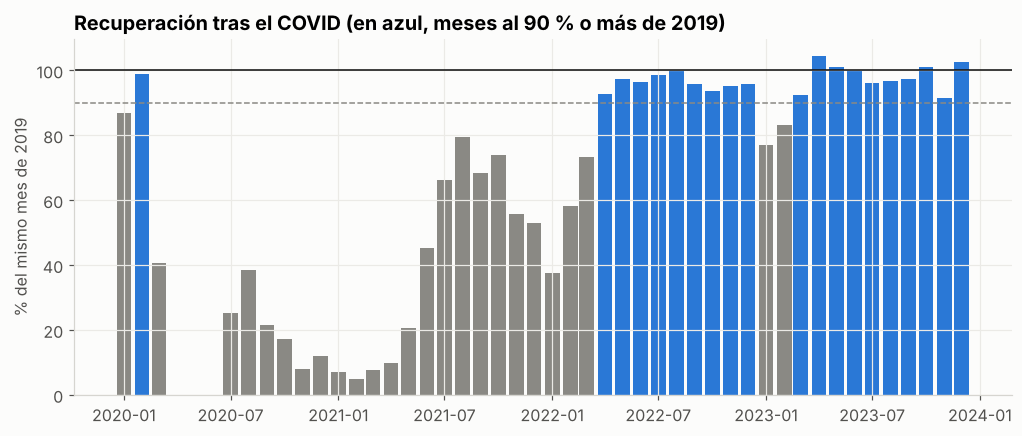

Meses por debajo del 90 % de 2019 desde 2022:
2022-01    38.0
2022-02    58.0
2022-03    73.0
2023-01    77.0
2023-02    83.0

Enero+febrero en % de 2019 · 2024: 96 · 2025: 94 · 2026: 96


In [9]:
base = y["2019"]
rec = pd.Series({f: y[f] / base[base.index.month == f.month].iloc[0] * 100
                 for f in y["2020":"2023"].index})

fig, ax = plt.subplots()
ax.bar(rec.index, rec.fillna(0), width=25, color=np.where(rec >= 90, AZUL, GRIS))
ax.axhline(100, color="#0b0b0b", lw=1); ax.axhline(90, color=GRIS, lw=1, ls="--")
ax.set_ylabel("% del mismo mes de 2019")
ax.set_title("Recuperación tras el COVID (en azul, meses al 90 % o más de 2019)")
guardar("08_recuperacion_covid")

print("Meses por debajo del 90 % de 2019 desde 2022:")
print(rec["2022":][rec["2022":] < 90].round(0).rename(lambda f: f"{f:%Y-%m}").to_string())
ene_feb = y[y.index.month.isin([1, 2])]
print("\nEnero+febrero en % de 2019 · 2024:", round(ene_feb["2024"].sum() / ene_feb["2019"].sum() * 100),
      "· 2025:", round(ene_feb["2025"].sum() / ene_feb["2019"].sum() * 100),
      "· 2026:", round(ene_feb["2026"].sum() / ene_feb["2019"].sum() * 100))

**Lectura:**
- Enero a marzo de 2022 siguen muy por debajo de 2019 (38 %, 58 % y 73 %), por la ola de ómicron.
  **Desde abril de 2022** los meses de temporada vuelven al 93–100 % de 2019.
- Enero y febrero de 2023 vuelven a quedar por debajo del 90 % (77 % y 83 %). Pero no parece
  COVID: los inviernos siguen por debajo de 2019 también en 2024–2026 (sección 2). Es la
  debilidad estructural del invierno, no la pandemia.

**Decisión:** el periodo COVID va de **marzo de 2020 a marzo de 2022** (25 meses). Así queda en la
columna `covid` que genera `src/descarga.py`.

**Para el modelo:**
- Esos meses no se usan para evaluar.
- Para entrenar, compararemos dos opciones: quitarlos o marcarlos con la variable `covid`.
- Ojo con los retardos: en 2023, el dato de "hace 12 meses" sigue contaminado hasta marzo.

## 8. El aeropuerto como indicador adelantado

Pasajeros del aeropuerto de Alicante-Elche (Eurostat). Comparamos la **variación interanual**
(cada mes frente al mismo mes del año anterior) de los pasajeros internacionales con la de las
pernoctaciones de extranjeros, con distintos desfases. Se excluyen los meses COVID.

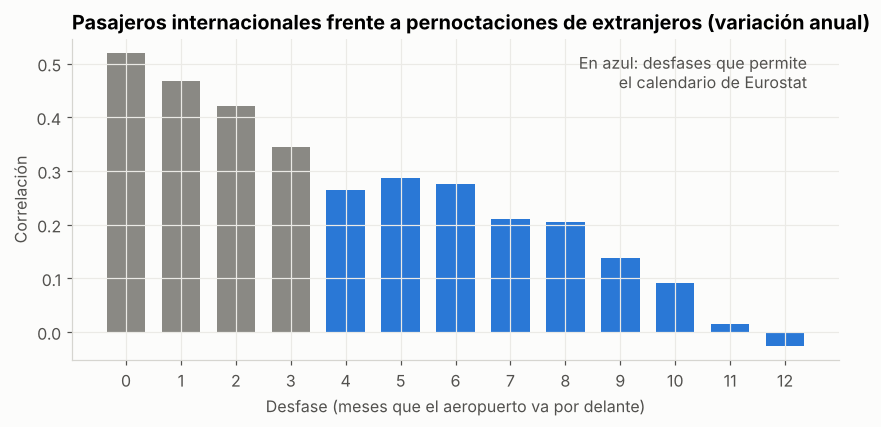

{0: 0.52, 1: 0.47, 2: 0.42, 3: 0.34, 4: 0.26, 5: 0.29, 6: 0.28, 7: 0.21, 8: 0.2, 9: 0.14, 10: 0.09, 11: 0.01, 12: -0.03}
Último mes INE: 2026-09 · último mes Eurostat: 2026-06
Pernoctaciones de extranjeros por pasajero internacional: {2005: 1.08, 2015: 0.87, 2019: 0.69, 2025: 0.62}


In [10]:
yoy = lambda s: np.log(s.where(s > 0)).diff(12)
aero_i, pern_x = yoy(d["aeropuerto_pasajeros_intl"]), yoy(d["costa_blanca_pernoctaciones_ext"])
ok = d.covid.eq(0) & d.covid.shift(12).eq(0)

corr = {}
for k in range(0, 13):
    m = ok & ok.shift(k) & aero_i.shift(k).notna() & pern_x.notna()
    corr[k] = np.corrcoef(aero_i.shift(k)[m], pern_x[m])[0, 1]
corr = pd.Series(corr)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(corr.index, corr, color=[AZUL if k >= 4 else GRIS for k in corr.index], width=0.7)
ax.set_xticks(corr.index)
ax.set_xlabel("Desfase (meses que el aeropuerto va por delante)")
ax.set_ylabel("Correlación")
ax.set_title("Pasajeros internacionales frente a pernoctaciones de extranjeros (variación anual)")
ax.text(12.4, corr.max(), "En azul: desfases que permite\nel calendario de Eurostat", ha="right", va="top", color="#52514e")
guardar("09_aeropuerto_desfase")
print(corr.round(2).to_dict())

ultimo_ine, ultimo_aero = d.index.max(), d["aeropuerto_pasajeros_total"].last_valid_index()
print(f"Último mes INE: {ultimo_ine:%Y-%m} · último mes Eurostat: {ultimo_aero:%Y-%m}")

r = (d["costa_blanca_pernoctaciones_ext"] / d["aeropuerto_pasajeros_intl"]).groupby(d.index.year).mean()
print("Pernoctaciones de extranjeros por pasajero internacional:", r.loc[[2005, 2015, 2019, 2025]].round(2).to_dict())

**Lectura:**
- La relación existe, pero es moderada: 0,52 en el mismo mes, y baja poco a poco con el desfase.
  Hay que excluir también los meses cuyo año anterior era COVID; si no, la correlación sale
  inflada (por encima de 0,9) solo por la caída y la recuperación de la pandemia.
- **Además está el calendario de publicación.** Eurostat va tres meses por detrás del INE: hoy hay
  datos del INE hasta septiembre de 2026, pero del aeropuerto solo hasta junio. Para prever el mes
  siguiente al último dato del INE, el último dato del aeropuerto disponible tiene **4 meses de desfase**
  (barras azules), y ahí la correlación es de solo 0,26.
- Otro dato interesante: cada pasajero internacional deja cada vez menos pernoctaciones hoteleras
  (1,08 en 2005 frente a 0,62 en 2025). El aeropuerto crece mucho más que la ocupación hotelera, lo que
  apunta a que buena parte de los turistas se aloja fuera de hoteles (viviendas turísticas, segundas residencias).

**Para el modelo:** el aeropuerto entra como candidata con desfase mínimo de 4 meses, y la fase 4 dirá
si aporta algo. Con datos de AENA, que salen unos 12 días después de cada mes, el desfase sería de
1–2 meses y la correlación sube a 0,4–0,5: es la mejora a probar si la variable resulta útil.

## 9. Autocorrelación y estacionariedad

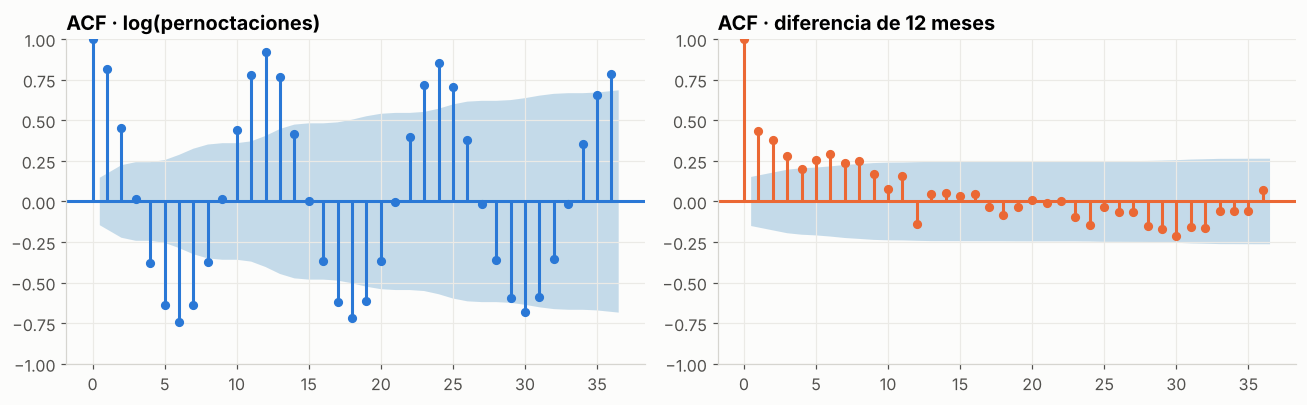

Test ADF (p-valor) · serie en log: 0.855 · diferencia estacional: 0.048
Fuerza de la estacionalidad (0–1): 0.98


In [11]:
ly = np.log(y["2005":"2019"])                     # tramo estable, sin COVID
sd = ly.diff(12).dropna()                          # diferencia estacional

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(ly, lags=36, ax=axes[0], color=AZUL, vlines_kwargs={"colors": AZUL}, title="ACF · log(pernoctaciones)")
plot_acf(sd, lags=36, ax=axes[1], color=NARANJA, vlines_kwargs={"colors": NARANJA}, title="ACF · diferencia de 12 meses")
for ax in axes:
    ax.title.set_fontsize(11)
plt.tight_layout()
guardar("10_autocorrelacion")

p1 = adfuller(ly, autolag="AIC")[1]; p2 = adfuller(sd, autolag="AIC")[1]
print(f"Test ADF (p-valor) · serie en log: {p1:.3f} · diferencia estacional: {p2:.3f}")

stl = STL(ly, period=12, robust=True).fit()
fuerza_est = 1 - stl.resid.var() / (stl.seasonal + stl.resid).var()
print(f"Fuerza de la estacionalidad (0–1): {fuerza_est:.2f}")

**Lectura:**
- La autocorrelación de la serie es la de un patrón estacional casi perfecto (picos en 12, 24 y 36 meses).
  La fuerza de la estacionalidad (descomposición STL) es de 0,98 sobre 1.
- La serie en logaritmos no es estacionaria (p ≈ 0,86). Con la diferencia de 12 meses pasa a serlo
  (p ≈ 0,05), y queda una autocorrelación positiva en los primeros meses (0,44 en el retardo 1).
  Es decir, **si un mes va mejor que el año anterior, el siguiente también suele ir mejor**.

**Para el modelo:**
- Trabajar en logaritmos.
- SARIMA con diferencia estacional (D = 1) y términos AR de orden bajo.
- En LightGBM: retardos 1, 2, 3 y 12, y la variación interanual del último mes conocido.

## 10. Modelo de referencia

El modelo más sencillo posible: **"este mes será igual que el mismo mes del año pasado"**
(ingenuo estacional). Todo lo que hagamos en las fases 3 y 4 tiene que mejorarlo.

In [12]:
def mape(real, pred):
    m = real.notna() & pred.notna()
    return (np.abs(real[m] - pred[m]) / real[m]).mean() * 100

ingenuo = y.shift(12)
res = pd.Series({
    "2015–2019": mape(y["2015":"2019"], ingenuo["2015":"2019"]),
    "2023–2025": mape(y["2023":"2025"], ingenuo["2023":"2025"]),
    "2024–2026": mape(y["2024":"2026"], ingenuo["2024":"2026"]),
}).round(2)
print("Error medio absoluto porcentual (MAPE) del ingenuo estacional:")
print(res.to_string())

err = ((y - ingenuo) / y * 100)["2024":"2026"]
print("\nMeses con más error 2024–2026:")
print(err.abs().sort_values(ascending=False).head(4).round(1).to_string())
res.to_frame("mape_ingenuo_estacional").to_csv(RAIZ / "outputs" / "baseline_ingenuo.csv")

Error medio absoluto porcentual (MAPE) del ingenuo estacional:
2015–2019    4.77
2023–2025    7.66
2024–2026    4.56

Meses con más error 2024–2026:
fecha
2024-02-01    18.4
2024-03-01    15.4
2024-01-01    14.6
2024-05-01    11.3


**Lectura:** el ingenuo estacional se equivoca de media un **4,8 %** en 2015–2019, un **7,7 %**
en 2023–2025 (2023 compara con un 2022 aún afectado por el COVID) y un **4,6 %** en 2024–2026.
Sus peores meses recientes son enero a marzo de 2024: copian un invierno de 2023 todavía flojo,
y en 2024 la Semana Santa pasó de abril a marzo.

Ese es el listón que tienen que bajar los modelos.

## 11. Conclusiones y decisiones para modelar

| Tema | Hallazgo | Decisión |
|---|---|---|
| Variable objetivo | Pernoctaciones totales de la Costa Blanca, 1999–2026 | Modelar en logaritmos. Benidorm como segunda serie |
| Estacionalidad | Muy fuerte (0,98) y cada vez más concentrada en verano (agosto/enero: 2,2 → 3,25) | Retardos de 12 meses y más peso a los años recientes; no asumir un perfil fijo |
| Residentes / extranjeros | Extranjeros, 61 % y subiendo; calendarios distintos | Comparar el modelo del total con la suma de dos modelos |
| Benidorm | Estancado desde 2005; el crecimiento viene del resto de la costa | Serie aparte |
| Oferta | Plazas +56 %, estancia media de 5,8 a 3,8 noches | Plazas como variable con retardo |
| Semana Santa | Desplaza ~4 puntos de peso entre marzo y abril | Variable `dias_semana_santa` (conocida de antemano) |
| COVID | Afecta de marzo de 2020 a marzo de 2022; después, solo la debilidad del invierno | Fuera de la evaluación; probar a quitarlo o marcarlo al entrenar |
| Aeropuerto | Correlación moderada (0,52) que cae a 0,26 con el desfase de publicación de Eurostat | Candidata con desfase ≥ 4; si aporta, pasar a datos de AENA |
| Referencia | Ingenuo estacional: MAPE 4,8 % (2015–2019), 7,7 % (2023–2025), 4,6 % (2024–2026) | Listón a batir |

**Esquema de validación para las fases 3 y 4:** origen móvil (backtesting) con ventana creciente.
Se entrena hasta un mes, se predice a 1–12 meses vista y se avanza un mes. Evaluación en 2023–2026,
sin mezclar nunca meses futuros en el entrenamiento.